In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files
import os

print("Select Crop_recommendation.csv from D:\\smart_agri\\data\\")
uploaded = files.upload()

# Colab saves uploaded files to /content/
# Rename if needed
for fn in uploaded.keys():
    print(f"Uploaded: {fn} ({len(uploaded[fn])} bytes)")

Select Crop_recommendation.csv from D:\smart_agri\data\


Saving Crop_recommendation.csv to Crop_recommendation.csv
Uploaded: Crop_recommendation.csv (150034 bytes)


In [ ]:
import pandas as pd

df = pd.read_csv("/content/Crop_recommendation.csv")

print(f"Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nDtypes:\n{df.dtypes}")
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nBasic statistics:")
print(df.describe())
print(f"\nCrop label distribution:")
print(df['label'].value_counts())

Shape: (2200, 8)

Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Dtypes:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

First 5 rows:
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice

Basic statistics:
                 N            P            K  temperature     humidity  \
count  2200.000000  2200.000000  2200.000000  2200.000000  2200.000000   
mean     50.551818    53.362727    48.149091    25.616244    71.481779   
std      36.917334    32.985883    50.647931

In [ ]:
import numpy as np

# Keep only features the Pi sensors actually provide
FEATURES = ["N", "P", "K", "temperature", "humidity"]
X_full = df[FEATURES].copy()

print(f"Feature columns: {FEATURES}")
print(f"Feature ranges:")
for col in FEATURES:
    print(f"  {col:12s}  min={X_full[col].min():7.2f}  max={X_full[col].max():7.2f}  mean={X_full[col].mean():7.2f}")

# ---- Fertilizer labeling rules ----
N_LOW, N_HIGH = 50, 100
P_LOW, P_HIGH = 40, 80
K_LOW, K_HIGH = 40, 80

def label_fertilizer(row):
    n, p, k = row["N"], row["P"], row["K"]
    n_def = n < N_LOW
    p_def = p < P_LOW
    k_def = k < K_LOW
    n_ok  = n >= N_HIGH
    p_ok  = p >= P_HIGH
    k_ok  = k >= K_HIGH

    if n_ok and p_ok and k_ok:
        return "No_fertilizer"
    if n_def and p_def and k_def:
        return "NPK_20_20_20"
    if n_def and p_ok and k_ok:
        return "Urea"
    if n_def and p_def and k_ok:
        return "DAP"
    if n_ok and p_ok and k_def:
        return "MOP"
    if n_ok and p_def and k_def:
        return "NPK_10_26_26"
    # Fallback for partial deficiencies
    deficits = {"N": N_LOW - n, "P": P_LOW - p, "K": K_LOW - k}
    worst = max(deficits, key=deficits.get)
    if worst == "N":
        return "Urea"
    elif worst == "P":
        return "DAP"
    else:
        return "MOP"

y_full = X_full.apply(label_fertilizer, axis=1)
print(f"\nFertilizer class distribution:")
print(y_full.value_counts())
print(f"\nTotal: {len(y_full)} rows, {y_full.nunique()} classes")

Feature columns: ['N', 'P', 'K', 'temperature', 'humidity']
Feature ranges:
  N             min=   0.00  max= 140.00  mean=  50.55
  P             min=   5.00  max= 145.00  mean=  53.36
  K             min=   5.00  max= 205.00  mean=  48.15
  temperature   min=   8.83  max=  43.68  mean=  25.62
  humidity      min=  14.26  max=  99.98  mean=  71.48

Fertilizer class distribution:
Urea            794
MOP             657
NPK_20_20_20    378
DAP             296
NPK_10_26_26     75
Name: count, dtype: int64

Total: 2200 rows, 5 classes


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y_full)
CLASSES = list(le.classes_)
NUM_CLASSES = len(CLASSES)

print(f"Classes ({NUM_CLASSES}):")
for i, c in enumerate(CLASSES):
    print(f"  {i}: {c}")

# Stratified split — preserves class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X_full.values, y_encoded,
    test_size=0.2, random_state=42, stratify=y_encoded,
)

print(f"\nTrain: {len(X_train)}  Test: {len(X_test)}")

from collections import Counter
print(f"\nTrain class counts:")
train_counts = Counter(y_train)
for i, c in enumerate(CLASSES):
    print(f"  {c:18s}  {train_counts.get(i, 0):5d}")

Classes (5):
  0: DAP
  1: MOP
  2: NPK_10_26_26
  3: NPK_20_20_20
  4: Urea

Train: 1760  Test: 440

Train class counts:
  DAP                   237
  MOP                   526
  NPK_10_26_26           60
  NPK_20_20_20          302
  Urea                  635


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time

# Class weighting handles imbalance automatically
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    class_weight="balanced",   # ← key for imbalanced classes
    random_state=42,
    n_jobs=-1,
)

t0 = time.time()
model.fit(X_train, y_train)
train_time = time.time() - t0
print(f"Training time: {train_time:.2f}s")

# Evaluate
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\nTest accuracy: {acc:.4f}")

print(f"\nPer-class report:")
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

Training time: 0.84s

Test accuracy: 0.9886

Per-class report:
              precision    recall  f1-score   support

         DAP      1.000     0.966     0.983        59
         MOP      0.963     1.000     0.981       131
NPK_10_26_26      1.000     1.000     1.000        15
NPK_20_20_20      1.000     1.000     1.000        76
        Urea      1.000     0.981     0.990       159

    accuracy                          0.989       440
   macro avg      0.993     0.989     0.991       440
weighted avg      0.989     0.989     0.989       440



In [ ]:
import joblib, json, os

SAVE_DIR = "/content/drive/MyDrive/smart_agri"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save the trained model
MODEL_PATH = f"{SAVE_DIR}/fert_model.pkl"
joblib.dump(model, MODEL_PATH)
print(f"Saved: {MODEL_PATH}")
print(f"Size: {os.path.getsize(MODEL_PATH) / 1e6:.2f} MB")

# Save the class list
CLASSES_PATH = f"{SAVE_DIR}/fert_classes.json"
with open(CLASSES_PATH, "w") as f:
    json.dump(CLASSES, f, indent=2)
print(f"Saved: {CLASSES_PATH}  ({len(CLASSES)} classes)")

# Save feature order (must match at inference time on the Pi)
FEATURES_PATH = f"{SAVE_DIR}/fert_features.json"
with open(FEATURES_PATH, "w") as f:
    json.dump(FEATURES, f, indent=2)
print(f"Saved: {FEATURES_PATH}  ({FEATURES})")

Saved: /content/drive/MyDrive/smart_agri/fert_model.pkl
Size: 2.86 MB
Saved: /content/drive/MyDrive/smart_agri/fert_classes.json  (5 classes)
Saved: /content/drive/MyDrive/smart_agri/fert_features.json  (['N', 'P', 'K', 'temperature', 'humidity'])


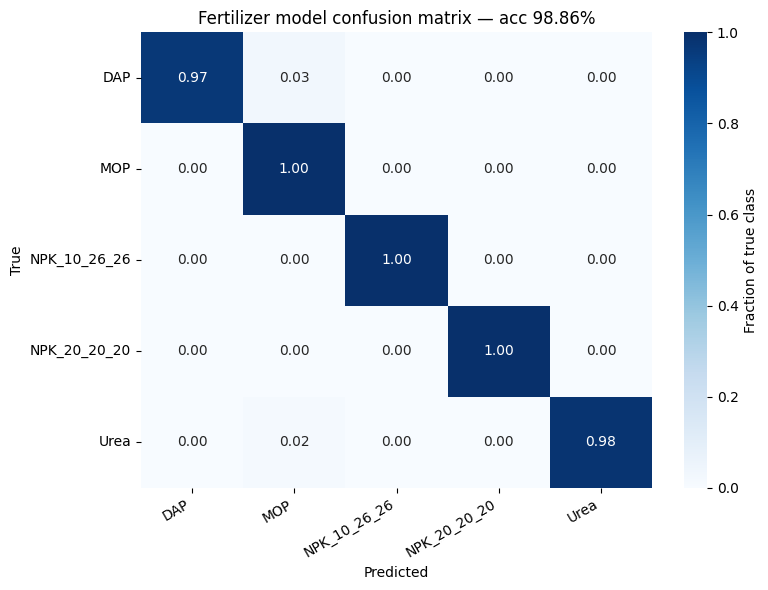

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
            cbar_kws={"label": "Fraction of true class"})
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Fertilizer model confusion matrix — acc {acc:.2%}")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fert_confusion_matrix.png", dpi=120)
plt.show()

In [ ]:
# Reference nutrient requirements per crop (kg of nutrient per quintal of target yield)
# Values based on ICAR general recommendations, simplified for demo
# Format: crop_keyword → {"N": kg_per_quintal, "P2O5": kg_per_quintal, "K2O": kg_per_quintal}

CROP_REQUIREMENTS = {
    "Tomato":   {"N": 1.20, "P2O5": 0.60, "K2O": 0.80},
    "Potato":   {"N": 1.50, "P2O5": 0.80, "K2O": 1.20},
    "Pepper":   {"N": 1.10, "P2O5": 0.55, "K2O": 0.75},
    "Corn":     {"N": 1.40, "P2O5": 0.70, "K2O": 0.60},
    "Apple":    {"N": 0.90, "P2O5": 0.45, "K2O": 0.70},
    "Grape":    {"N": 0.80, "P2O5": 0.40, "K2O": 0.90},
    "Cherry":   {"N": 0.85, "P2O5": 0.40, "K2O": 0.65},
    "Peach":    {"N": 0.90, "P2O5": 0.45, "K2O": 0.70},
    "Strawberry": {"N": 1.00, "P2O5": 0.50, "K2O": 0.85},
    "Blueberry": {"N": 0.70, "P2O5": 0.35, "K2O": 0.55},
    "Raspberry": {"N": 0.75, "P2O5": 0.35, "K2O": 0.60},
    "Soybean":  {"N": 0.40, "P2O5": 0.80, "K2O": 0.60},  # N-fixing crop
    "Squash":   {"N": 1.10, "P2O5": 0.55, "K2O": 0.90},
    "Default":  {"N": 1.00, "P2O5": 0.50, "K2O": 0.70},
}

def get_crop_requirements(disease_class):
    """Extract crop name from a disease class string and return nutrient requirements."""
    # Disease classes look like "Tomato___Early_blight", "Potato___Late_blight", etc.
    # Extract the part before the first underscore
    crop = disease_class.split("___")[0].split("_")[0]
    return CROP_REQUIREMENTS.get(crop, CROP_REQUIREMENTS["Default"])

# Quick test
for cls in ["Tomato___Early_blight", "Potato___Late_blight", "Corn___Common_rust"]:
    req = get_crop_requirements(cls)
    print(f"{cls:35s} → {req}")

Tomato___Early_blight               → {'N': 1.2, 'P2O5': 0.6, 'K2O': 0.8}
Potato___Late_blight                → {'N': 1.5, 'P2O5': 0.8, 'K2O': 1.2}
Corn___Common_rust                  → {'N': 1.4, 'P2O5': 0.7, 'K2O': 0.6}


In [ ]:
# Fertilizer nutrient content (fraction of N, P2O5, K2O per kg of product)
FERTILIZER_COMPOSITION = {
    "Urea":         {"N": 0.46, "P2O5": 0.00, "K2O": 0.00},
    "DAP":          {"N": 0.18, "P2O5": 0.46, "K2O": 0.00},
    "MOP":          {"N": 0.00, "P2O5": 0.00, "K2O": 0.60},
    "NPK_10_26_26": {"N": 0.10, "P2O5": 0.26, "K2O": 0.26},
    "NPK_20_20_20": {"N": 0.20, "P2O5": 0.20, "K2O": 0.20},
    "No_fertilizer":{"N": 0.00, "P2O5": 0.00, "K2O": 0.00},
}

def calculate_dosage(fertilizer_type, disease_class, target_yield_quintals=20):
    """
    Calculate fertilizer dosage in kg/hectare.

    Args:
        fertilizer_type: one of the 6 classes predicted by the ML model
        disease_class: the disease class string (e.g., "Tomato___Early_blight")
        target_yield_quintals: farmer's target yield (default 20 quintal/ha)

    Returns:
        dict with fertilizer_type, dosage_kg_per_ha, and reasoning
    """
    if fertilizer_type == "No_fertilizer":
        return {
            "fertilizer_type": "No_fertilizer",
            "dosage_kg_per_ha": 0,
            "reasoning": "Soil nutrient levels are adequate for the target crop.",
        }

    req = get_crop_requirements(disease_class)
    comp = FERTILIZER_COMPOSITION[fertilizer_type]

    # Total nutrients needed for the target yield
    need_N    = req["N"]    * target_yield_quintals
    need_P2O5 = req["P2O5"] * target_yield_quintals
    need_K2O  = req["K2O"]  * target_yield_quintals

    # Determine which nutrient the fertilizer is meant to supply
    # (primary nutrient = whichever is highest in the fertilizer composition)
    primary_nutrient = max(comp, key=comp.get)
    primary_amount_needed = {
        "N": need_N, "P2O5": need_P2O5, "K2O": need_K2O
    }[primary_nutrient]

    # Dosage = nutrient needed / fraction in fertilizer
    if comp[primary_nutrient] == 0:
        return {
            "fertilizer_type": fertilizer_type,
            "dosage_kg_per_ha": 0,
            "reasoning": "Fertilizer composition has no primary nutrient — check inputs.",
        }

    dosage = primary_amount_needed / comp[primary_nutrient]

    # Clamp to reasonable bounds (agronomic practice: 20–500 kg/ha)
    dosage = max(20, min(500, dosage))

    return {
        "fertilizer_type": fertilizer_type,
        "dosage_kg_per_ha": round(dosage, 1),
        "reasoning": f"To achieve {target_yield_quintals} quintal/ha of "
                     f"{disease_class.split('___')[0]}, apply {round(dosage, 1)} kg/ha "
                     f"of {fertilizer_type} (supplying {primary_nutrient}).",
    }

# Quick test
for fert in ["Urea", "DAP", "MOP", "NPK_20_20_20", "No_fertilizer"]:
    result = calculate_dosage(fert, "Tomato___Early_blight", target_yield_quintals=20)
    print(f"{fert:15s} → {result['dosage_kg_per_ha']:6.1f} kg/ha  |  {result['reasoning']}")

Urea            →   52.2 kg/ha  |  To achieve 20 quintal/ha of Tomato, apply 52.2 kg/ha of Urea (supplying N).
DAP             →   26.1 kg/ha  |  To achieve 20 quintal/ha of Tomato, apply 26.1 kg/ha of DAP (supplying P2O5).
MOP             →   26.7 kg/ha  |  To achieve 20 quintal/ha of Tomato, apply 26.7 kg/ha of MOP (supplying K2O).
NPK_20_20_20    →  120.0 kg/ha  |  To achieve 20 quintal/ha of Tomato, apply 120.0 kg/ha of NPK_20_20_20 (supplying N).
No_fertilizer   →    0.0 kg/ha  |  Soil nutrient levels are adequate for the target crop.


In [ ]:
# Simulate 5 sensor readings + disease predictions
test_cases = [
    # (N, P, K, temp, humidity, disease_class)
    (20, 60, 60, 25.0, 70.0, "Tomato___Early_blight"),      # N deficient → Urea
    (20, 30, 60, 24.0, 72.0, "Potato___Late_blight"),       # N and P deficient → DAP
    (80, 60, 20, 26.0, 68.0, "Tomato___Late_blight"),       # K deficient → MOP
    (30, 30, 30, 23.0, 75.0, "Corn___Common_rust"),         # All deficient → NPK 20-20-20
    (120, 100, 100, 22.0, 65.0, "Apple___Apple_scab"),      # All adequate → No fertilizer
]

print("=" * 100)
for n, p, k, t, h, disease in test_cases:
    features = np.array([[n, p, k, t, h]])
    fert_idx = model.predict(features)[0]
    fert_type = CLASSES[fert_idx]

    dosage_info = calculate_dosage(fert_type, disease, target_yield_quintals=20)

    print(f"\nSensor input:   N={n}, P={p}, K={k}, T={t}°C, H={h}%")
    print(f"Disease:        {disease}")
    print(f"Fertilizer:     {fert_type}")
    print(f"Dosage:         {dosage_info['dosage_kg_per_ha']} kg/ha")
    print(f"Reasoning:      {dosage_info['reasoning']}")
print("\n" + "=" * 100)


Sensor input:   N=20, P=60, K=60, T=25.0°C, H=70.0%
Disease:        Tomato___Early_blight
Fertilizer:     Urea
Dosage:         52.2 kg/ha
Reasoning:      To achieve 20 quintal/ha of Tomato, apply 52.2 kg/ha of Urea (supplying N).

Sensor input:   N=20, P=30, K=60, T=24.0°C, H=72.0%
Disease:        Potato___Late_blight
Fertilizer:     Urea
Dosage:         65.2 kg/ha
Reasoning:      To achieve 20 quintal/ha of Potato, apply 65.2 kg/ha of Urea (supplying N).

Sensor input:   N=80, P=60, K=20, T=26.0°C, H=68.0%
Disease:        Tomato___Late_blight
Fertilizer:     MOP
Dosage:         26.7 kg/ha
Reasoning:      To achieve 20 quintal/ha of Tomato, apply 26.7 kg/ha of MOP (supplying K2O).

Sensor input:   N=30, P=30, K=30, T=23.0°C, H=75.0%
Disease:        Corn___Common_rust
Fertilizer:     NPK_20_20_20
Dosage:         140.0 kg/ha
Reasoning:      To achieve 20 quintal/ha of Corn, apply 140.0 kg/ha of NPK_20_20_20 (supplying N).

Sensor input:   N=120, P=100, K=100, T=22.0°C, H=65.0%
Disease: 

In [ ]:
print("=" * 60)
print("FERTILIZER MODEL — FINAL SUMMARY")
print("=" * 60)
print(f"  Input features:        {FEATURES}")
print(f"  Number of classes:     {NUM_CLASSES}")
print(f"  Classes:               {CLASSES}")
print(f"  Test accuracy:         {acc:.4f}")
print(f"  Model size:            {os.path.getsize(MODEL_PATH) / 1e6:.2f} MB")
print(f"  Saved to Drive:        {SAVE_DIR}")
print(f"    - fert_model.pkl")
print(f"    - fert_classes.json")
print(f"    - fert_features.json")
print(f"    - fert_confusion_matrix.png")
print("=" * 60)

FERTILIZER MODEL — FINAL SUMMARY
  Input features:        ['N', 'P', 'K', 'temperature', 'humidity']
  Number of classes:     5
  Classes:               ['DAP', 'MOP', 'NPK_10_26_26', 'NPK_20_20_20', 'Urea']
  Test accuracy:         0.9886
  Model size:            2.86 MB
  Saved to Drive:        /content/drive/MyDrive/smart_agri
    - fert_model.pkl
    - fert_classes.json
    - fert_features.json
    - fert_confusion_matrix.png


In [ ]:
import numpy as np
import joblib
import json

# Load model and metadata from Drive
SAVE_DIR = "/content/drive/MyDrive/smart_agri"
model = joblib.load(f"{SAVE_DIR}/fert_model.pkl")
with open(f"{SAVE_DIR}/fert_classes.json") as f:
    FERT_CLASSES = json.load(f)
with open(f"{SAVE_DIR}/fert_features.json") as f:
    FEATURES = json.load(f)

print(f"Model loaded. Classes: {FERT_CLASSES}")
print(f"Input features: {FEATURES}")

# --- Interactive test function ---
def predict_fertilizer(N, P, K, temperature, humidity):
    """Predict fertilizer class from sensor readings."""
    x = np.array([[N, P, K, temperature, humidity]])
    idx = model.predict(x)[0]
    proba = model.predict_proba(x)[0]
    return FERT_CLASSES[idx], proba

# --- 10 hand-crafted test cases ---
test_cases = [
    # (N,   P,   K,   temp,  humidity, expected_reason)
    (25,  60,  60,  25.0, 70.0, "N deficient → expect Urea"),
    (85,  60,  60,  25.0, 70.0, "N borderline → expect Urea or No_fert"),
    (100, 90,  90,  25.0, 70.0, "All adequate → expect No_fert (if class exists)"),
    (25,  30,  60,  25.0, 70.0, "N + P deficient → expect DAP"),
    (85,  90,  25,  25.0, 70.0, "K alone deficient → expect MOP"),
    (85,  30,  25,  25.0, 70.0, "P + K deficient → expect NPK 10-26-26"),
    (25,  30,  25,  25.0, 70.0, "All deficient → expect NPK 20-20-20"),
    (100, 100, 100, 25.0, 70.0, "All well above → expect No_fert"),
    (50,  50,  50,  25.0, 70.0, "All borderline → mixed prediction expected"),
    (120, 50,  50,  25.0, 70.0, "N high, P/K borderline → expect Urea avoided, maybe No_fert"),
]

print("\n" + "=" * 110)
print(f"{'N':>4} {'P':>4} {'K':>4} {'T':>5} {'H':>5} | {'Prediction':<15} | {'Confidence':<10} | Reason")
print("=" * 110)

for N, P, K, T, H, reason in test_cases:
    fert, proba = predict_fertilizer(N, P, K, T, H)
    conf = proba.max()
    print(f"{N:>4} {P:>4} {K:>4} {T:>5.1f} {H:>5.1f} | {fert:<15} | {conf:>6.2%}     | {reason}")

Model loaded. Classes: ['DAP', 'MOP', 'NPK_10_26_26', 'NPK_20_20_20', 'Urea']
Input features: ['N', 'P', 'K', 'temperature', 'humidity']

   N    P    K     T     H | Prediction      | Confidence | Reason
  25   60   60  25.0  70.0 | Urea            | 87.81%     | N deficient → expect Urea
  85   60   60  25.0  70.0 | MOP             | 97.88%     | N borderline → expect Urea or No_fert
 100   90   90  25.0  70.0 | MOP             | 59.13%     | All adequate → expect No_fert (if class exists)
  25   30   60  25.0  70.0 | Urea            | 40.36%     | N + P deficient → expect DAP
  85   90   25  25.0  70.0 | MOP             | 95.16%     | K alone deficient → expect MOP
  85   30   25  25.0  70.0 | MOP             | 76.49%     | P + K deficient → expect NPK 10-26-26
  25   30   25  25.0  70.0 | NPK_20_20_20    | 84.11%     | All deficient → expect NPK 20-20-20
 100  100  100  25.0  70.0 | MOP             | 58.63%     | All well above → expect No_fert
  50   50   50  25.0  70.0 | Urea    

In [ ]:
# Reuse calculate_dosage from Cell 10 — redefine here in case it was lost
FERTILIZER_COMPOSITION = {
    "Urea":         {"N": 0.46, "P2O5": 0.00, "K2O": 0.00},
    "DAP":          {"N": 0.18, "P2O5": 0.46, "K2O": 0.00},
    "MOP":          {"N": 0.00, "P2O5": 0.00, "K2O": 0.60},
    "NPK_10_26_26": {"N": 0.10, "P2O5": 0.26, "K2O": 0.26},
    "NPK_20_20_20": {"N": 0.20, "P2O5": 0.20, "K2O": 0.20},
}

CROP_REQUIREMENTS = {
    "Tomato":   {"N": 1.20, "P2O5": 0.60, "K2O": 0.80},
    "Potato":   {"N": 1.50, "P2O5": 0.80, "K2O": 1.20},
    "Corn":     {"N": 1.40, "P2O5": 0.70, "K2O": 0.60},
    "Apple":    {"N": 0.90, "P2O5": 0.45, "K2O": 0.70},
    "Default":  {"N": 1.00, "P2O5": 0.50, "K2O": 0.70},
}

def get_crop_requirements(disease_class):
    crop = disease_class.split("___")[0].split("_")[0]
    return CROP_REQUIREMENTS.get(crop, CROP_REQUIREMENTS["Default"])

def calculate_dosage(fertilizer_type, disease_class, target_yield=20):
    if fertilizer_type not in FERTILIZER_COMPOSITION:
        return {"fertilizer_type": fertilizer_type, "dosage_kg_per_ha": 0,
                "reasoning": "Unknown fertilizer — no dosage calculated."}
    req = get_crop_requirements(disease_class)
    comp = FERTILIZER_COMPOSITION[fertilizer_type]
    primary = max(comp, key=comp.get)
    if comp[primary] == 0:
        return {"fertilizer_type": fertilizer_type, "dosage_kg_per_ha": 0,
                "reasoning": "No primary nutrient."}
    need = {"N": req["N"], "P2O5": req["P2O5"], "K2O": req["K2O"]}[primary] * target_yield
    dosage = max(20, min(500, need / comp[primary]))
    return {"fertilizer_type": fertilizer_type, "dosage_kg_per_ha": round(dosage, 1),
            "reasoning": f"Apply {round(dosage, 1)} kg/ha of {fertilizer_type} "
                         f"to supply {primary} for {disease_class.split('___')[0]}."}

# --- Full pipeline test ---
scenarios = [
    (25, 60, 60, 25.0, 70.0, "Tomato___Early_blight", "Tomato Early Blight"),
    (25, 30, 60, 24.0, 72.0, "Potato___Late_blight", "Potato Late Blight"),
    (85, 90, 25, 26.0, 68.0, "Corn___Common_rust", "Corn Common Rust"),
    (25, 30, 25, 23.0, 75.0, "Apple___Apple_scab", "Apple Scab"),
    (100, 90, 90, 22.0, 65.0, "Tomato___healthy", "Tomato Healthy"),
]

print("=" * 110)
for N, P, K, T, H, disease, label in scenarios:
    fert, proba = predict_fertilizer(N, P, K, T, H)
    dosage = calculate_dosage(fert, disease, target_yield=20)
    print(f"\nScenario: {label}")
    print(f"  Sensor readings:    N={N}, P={P}, K={K}, T={T}°C, H={H}%")
    print(f"  Disease detected:   {disease}")
    print(f"  Fertilizer:         {fert}  (confidence {proba.max():.1%})")
    print(f"  Dosage:             {dosage['dosage_kg_per_ha']} kg/ha")
    print(f"  Reasoning:          {dosage['reasoning']}")
print("\n" + "=" * 110)


Scenario: Tomato Early Blight
  Sensor readings:    N=25, P=60, K=60, T=25.0°C, H=70.0%
  Disease detected:   Tomato___Early_blight
  Fertilizer:         Urea  (confidence 97.7%)
  Dosage:             52.2 kg/ha
  Reasoning:          Apply 52.2 kg/ha of Urea to supply N for Tomato.

Scenario: Potato Late Blight
  Sensor readings:    N=25, P=30, K=60, T=24.0°C, H=72.0%
  Disease detected:   Potato___Late_blight
  Fertilizer:         DAP  (confidence 92.1%)
  Dosage:             34.8 kg/ha
  Reasoning:          Apply 34.8 kg/ha of DAP to supply P2O5 for Potato.

Scenario: Corn Common Rust
  Sensor readings:    N=85, P=90, K=25, T=26.0°C, H=68.0%
  Disease detected:   Corn___Common_rust
  Fertilizer:         MOP  (confidence 99.3%)
  Dosage:             20 kg/ha
  Reasoning:          Apply 20 kg/ha of MOP to supply K2O for Corn.

Scenario: Apple Scab
  Sensor readings:    N=25, P=30, K=25, T=23.0°C, H=75.0%
  Disease detected:   Apple___Apple_scab
  Fertilizer:         NPK_20_20_20  (con

In [ ]:
import numpy as np
import pandas as pd

FEATURES = ["N", "P", "K", "temperature", "humidity"]
np.random.seed(42)

# Generate realistic synthetic samples for each fertilizer class
# Feature ranges taken from typical agronomic deficiency ranges

def make_sample(n_range, p_range, k_range, t_range=(15, 35), h_range=(40, 95)):
    """Generate one sample with noise added."""
    n = np.random.uniform(*n_range)
    p = np.random.uniform(*p_range)
    k = np.random.uniform(*k_range)
    t = np.random.uniform(*t_range)
    h = np.random.uniform(*h_range)
    # Add ±3% noise to each feature to mimic real sensor behavior
    noise = 1.0 + np.random.uniform(-0.03, 0.03, size=5)
    vals = np.array([n, p, k, t, h]) * noise
    return vals.tolist()

supplementary = []

# No_fertilizer: all NPK adequate
for _ in range(300):
    supplementary.append(
        make_sample(n_range=(80, 140), p_range=(65, 130), k_range=(65, 180))
        + ["No_fertilizer"]
    )

# Urea: N low, P and K adequate
for _ in range(250):
    supplementary.append(
        make_sample(n_range=(10, 38), p_range=(45, 100), k_range=(45, 120))
        + ["Urea"]
    )

# DAP: N and P low, K adequate
for _ in range(250):
    supplementary.append(
        make_sample(n_range=(10, 38), p_range=(10, 38), k_range=(45, 120))
        + ["DAP"]
    )

# MOP: N and P adequate, K low
for _ in range(250):
    supplementary.append(
        make_sample(n_range=(45, 110), p_range=(45, 110), k_range=(10, 38))
        + ["MOP"]
    )

# NPK_10_26_26: P and K low, N adequate
for _ in range(250):
    supplementary.append(
        make_sample(n_range=(45, 110), p_range=(10, 38), k_range=(10, 38))
        + ["NPK_10_26_26"]
    )

# NPK_20_20_20: N low, P and K borderline-low (mixed deficiency)
for _ in range(250):
    supplementary.append(
        make_sample(n_range=(15, 38), p_range=(25, 55), k_range=(25, 55))
        + ["NPK_20_20_20"]
    )

supp_df = pd.DataFrame(supplementary, columns=FEATURES + ["fertilizer_class"])
print(f"Generated {len(supp_df)} supplementary samples")
print(f"\nDistribution:")
print(supp_df["fertilizer_class"].value_counts())
print(f"\nSample rows:")
print(supp_df.head())

Generated 1550 supplementary samples

Distribution:
fertilizer_class
No_fertilizer    300
Urea             250
DAP              250
MOP              250
NPK_10_26_26     250
NPK_20_20_20     250
Name: count, dtype: int64

Sample rows:
            N           P           K  temperature   humidity fertilizer_class
0  100.357343  123.434425  152.456857    27.136813  49.187528    No_fertilizer
1   79.691950  126.540202  160.969651    19.168192  49.374056    No_fertilizer
2  118.708167   72.732443   98.680843    22.451039  63.312724    No_fertilizer
3  118.607513   75.192121   70.731267    34.353300  92.775419    No_fertilizer
4   88.173803   96.088551   69.037707    33.279417  53.207424    No_fertilizer


In [ ]:
# Load the original CSV
df = pd.read_csv("/content/Crop_recommendation.csv")
X_real = df[FEATURES].copy()

# Apply the improved labeling rules
N_LOW, P_LOW, K_LOW = 40, 40, 40
N_OK,  P_OK,  K_OK  = 80, 60, 60

def label_fertilizer(row):
    n, p, k = row["N"], row["P"], row["K"]

    if n >= N_OK and p >= P_OK and k >= K_OK:
        return "No_fertilizer"

    n_def = n < N_LOW
    p_def = p < P_LOW
    k_def = k < K_LOW

    if n_def and p_def and k_def:
        return "NPK_20_20_20"
    if n_def and not p_def and not k_def:
        return "Urea"
    if n_def and p_def and not k_def:
        return "DAP"
    if n_def and not p_def and k_def:
        return "NPK_20_20_20"
    if not n_def and p_def and not k_def:
        return "DAP"
    if not n_def and p_def and k_def:
        return "NPK_10_26_26"
    if not n_def and not p_def and k_def:
        return "MOP"
    return "NPK_20_20_20"

y_real = X_real.apply(label_fertilizer, axis=1)

real_df = X_real.copy()
real_df["fertilizer_class"] = y_real

# Combined dataset
combined = pd.concat([real_df, supp_df], ignore_index=True)

print(f"Real samples:        {len(real_df)}")
print(f"Synthetic samples:   {len(supp_df)}")
print(f"Combined total:      {len(combined)}")

print(f"\nClass distribution (combined):")
print(combined["fertilizer_class"].value_counts())

Real samples:        2200
Synthetic samples:   1550
Combined total:      3750

Class distribution (combined):
fertilizer_class
NPK_20_20_20     1427
MOP               561
DAP               529
Urea              522
NPK_10_26_26      411
No_fertilizer     300
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from collections import Counter
import time, json, joblib, os

# Use the combined dataset
X_final = combined[FEATURES].values
y_labels = combined["fertilizer_class"].values

le = LabelEncoder()
y_encoded = le.fit_transform(y_labels)
CLASSES = list(le.classes_)
NUM_CLASSES = len(CLASSES)

print(f"Classes ({NUM_CLASSES}): {CLASSES}")

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_encoded,
    test_size=0.2, random_state=42, stratify=y_encoded,
)

print(f"\nTrain: {len(X_train)}  Test: {len(X_test)}")
tc = Counter(y_train)
print(f"\nTrain class counts:")
for i, c in enumerate(CLASSES):
    print(f"  {c:18s}  {tc.get(i, 0):5d}")

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

t0 = time.time()
model.fit(X_train, y_train)
print(f"\nTraining time: {time.time()-t0:.2f}s")

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\nTest accuracy: {acc:.4f}")

print(f"\nPer-class report:")
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

Classes (6): ['DAP', 'MOP', 'NPK_10_26_26', 'NPK_20_20_20', 'No_fertilizer', 'Urea']

Train: 3000  Test: 750

Train class counts:
  DAP                   423
  MOP                   449
  NPK_10_26_26          329
  NPK_20_20_20         1141
  No_fertilizer         240
  Urea                  418

Training time: 1.69s

Test accuracy: 0.9920

Per-class report:
               precision    recall  f1-score   support

          DAP      0.981     0.981     0.981       106
          MOP      1.000     1.000     1.000       112
 NPK_10_26_26      1.000     1.000     1.000        82
 NPK_20_20_20      0.990     0.990     0.990       286
No_fertilizer      1.000     1.000     1.000        60
         Urea      0.990     0.990     0.990       104

     accuracy                          0.992       750
    macro avg      0.994     0.994     0.994       750
 weighted avg      0.992     0.992     0.992       750



In [ ]:
SAVE_DIR = "/content/drive/MyDrive/smart_agri"
os.makedirs(SAVE_DIR, exist_ok=True)

joblib.dump(model, f"{SAVE_DIR}/fert_model.pkl")
with open(f"{SAVE_DIR}/fert_classes.json", "w") as f:
    json.dump(CLASSES, f, indent=2)
with open(f"{SAVE_DIR}/fert_features.json", "w") as f:
    json.dump(FEATURES, f, indent=2)

print(f"Saved: {SAVE_DIR}/fert_model.pkl")
print(f"Size: {os.path.getsize(f'{SAVE_DIR}/fert_model.pkl')/1e6:.2f} MB")
print(f"Classes: {CLASSES}")

Saved: /content/drive/MyDrive/smart_agri/fert_model.pkl
Size: 5.20 MB
Classes: ['DAP', 'MOP', 'NPK_10_26_26', 'NPK_20_20_20', 'No_fertilizer', 'Urea']


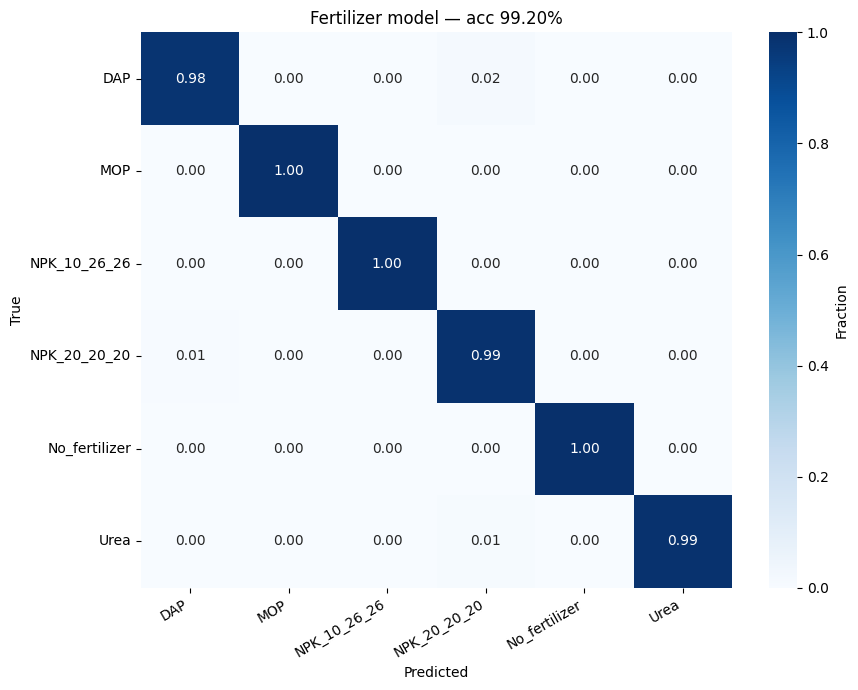

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
            cbar_kws={"label": "Fraction"})
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Fertilizer model — acc {acc:.2%}")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fert_confusion_matrix.png", dpi=120)
plt.show()

In [ ]:
import numpy as np
import joblib
import json

# Load model and metadata from Drive
SAVE_DIR = "/content/drive/MyDrive/smart_agri"
model = joblib.load(f"{SAVE_DIR}/fert_model.pkl")
with open(f"{SAVE_DIR}/fert_classes.json") as f:
    FERT_CLASSES = json.load(f)
with open(f"{SAVE_DIR}/fert_features.json") as f:
    FEATURES = json.load(f)

print(f"Model loaded. Classes: {FERT_CLASSES}")
print(f"Input features: {FEATURES}")

# --- Interactive test function ---
def predict_fertilizer(N, P, K, temperature, humidity):
    """Predict fertilizer class from sensor readings."""
    x = np.array([[N, P, K, temperature, humidity]])
    idx = model.predict(x)[0]
    proba = model.predict_proba(x)[0]
    return FERT_CLASSES[idx], proba

# --- 10 hand-crafted test cases ---
test_cases = [
    # (N,   P,   K,   temp,  humidity, expected_reason)
    (25,  60,  60,  25.0, 70.0, "N deficient → expect Urea"),
    (85,  60,  60,  25.0, 70.0, "N borderline → expect Urea or No_fert"),
    (100, 90,  90,  25.0, 70.0, "All adequate → expect No_fert (if class exists)"),
    (25,  30,  60,  25.0, 70.0, "N + P deficient → expect DAP"),
    (85,  90,  25,  25.0, 70.0, "K alone deficient → expect MOP"),
    (85,  30,  25,  25.0, 70.0, "P + K deficient → expect NPK 10-26-26"),
    (25,  30,  25,  25.0, 70.0, "All deficient → expect NPK 20-20-20"),
    (100, 100, 100, 25.0, 70.0, "All well above → expect No_fert"),
    (50,  50,  50,  25.0, 70.0, "All borderline → mixed prediction expected"),
    (120, 50,  50,  25.0, 70.0, "N high, P/K borderline → expect Urea avoided, maybe No_fert"),
]

print("\n" + "=" * 110)
print(f"{'N':>4} {'P':>4} {'K':>4} {'T':>5} {'H':>5} | {'Prediction':<15} | {'Confidence':<10} | Reason")
print("=" * 110)

for N, P, K, T, H, reason in test_cases:
    fert, proba = predict_fertilizer(N, P, K, T, H)
    conf = proba.max()
    print(f"{N:>4} {P:>4} {K:>4} {T:>5.1f} {H:>5.1f} | {fert:<15} | {conf:>6.2%}     | {reason}")

Model loaded. Classes: ['DAP', 'MOP', 'NPK_10_26_26', 'NPK_20_20_20', 'No_fertilizer', 'Urea']
Input features: ['N', 'P', 'K', 'temperature', 'humidity']

   N    P    K     T     H | Prediction      | Confidence | Reason
  25   60   60  25.0  70.0 | Urea            | 97.67%     | N deficient → expect Urea
  85   60   60  25.0  70.0 | NPK_20_20_20    | 55.39%     | N borderline → expect Urea or No_fert
 100   90   90  25.0  70.0 | No_fertilizer   | 99.33%     | All adequate → expect No_fert (if class exists)
  25   30   60  25.0  70.0 | DAP             | 93.53%     | N + P deficient → expect DAP
  85   90   25  25.0  70.0 | MOP             | 99.00%     | K alone deficient → expect MOP
  85   30   25  25.0  70.0 | NPK_10_26_26    | 100.00%     | P + K deficient → expect NPK 10-26-26
  25   30   25  25.0  70.0 | NPK_20_20_20    | 99.72%     | All deficient → expect NPK 20-20-20
 100  100  100  25.0  70.0 | No_fertilizer   | 99.33%     | All well above → expect No_fert
  50   50   50  25.

In [ ]:
# Reuse calculate_dosage from Cell 10 — redefine here in case it was lost
FERTILIZER_COMPOSITION = {
    "Urea":         {"N": 0.46, "P2O5": 0.00, "K2O": 0.00},
    "DAP":          {"N": 0.18, "P2O5": 0.46, "K2O": 0.00},
    "MOP":          {"N": 0.00, "P2O5": 0.00, "K2O": 0.60},
    "NPK_10_26_26": {"N": 0.10, "P2O5": 0.26, "K2O": 0.26},
    "NPK_20_20_20": {"N": 0.20, "P2O5": 0.20, "K2O": 0.20},
}

CROP_REQUIREMENTS = {
    "Tomato":   {"N": 1.20, "P2O5": 0.60, "K2O": 0.80},
    "Potato":   {"N": 1.50, "P2O5": 0.80, "K2O": 1.20},
    "Corn":     {"N": 1.40, "P2O5": 0.70, "K2O": 0.60},
    "Apple":    {"N": 0.90, "P2O5": 0.45, "K2O": 0.70},
    "Default":  {"N": 1.00, "P2O5": 0.50, "K2O": 0.70},
}

def get_crop_requirements(disease_class):
    crop = disease_class.split("___")[0].split("_")[0]
    return CROP_REQUIREMENTS.get(crop, CROP_REQUIREMENTS["Default"])

def calculate_dosage(fertilizer_type, disease_class, target_yield=20):
    if fertilizer_type not in FERTILIZER_COMPOSITION:
        return {"fertilizer_type": fertilizer_type, "dosage_kg_per_ha": 0,
                "reasoning": "Unknown fertilizer — no dosage calculated."}
    req = get_crop_requirements(disease_class)
    comp = FERTILIZER_COMPOSITION[fertilizer_type]
    primary = max(comp, key=comp.get)
    if comp[primary] == 0:
        return {"fertilizer_type": fertilizer_type, "dosage_kg_per_ha": 0,
                "reasoning": "No primary nutrient."}
    need = {"N": req["N"], "P2O5": req["P2O5"], "K2O": req["K2O"]}[primary] * target_yield
    dosage = max(20, min(500, need / comp[primary]))
    return {"fertilizer_type": fertilizer_type, "dosage_kg_per_ha": round(dosage, 1),
            "reasoning": f"Apply {round(dosage, 1)} kg/ha of {fertilizer_type} "
                         f"to supply {primary} for {disease_class.split('___')[0]}."}

# --- Full pipeline test ---
scenarios = [
    (25, 60, 60, 25.0, 70.0, "Tomato___Early_blight", "Tomato Early Blight"),
    (25, 30, 60, 24.0, 72.0, "Potato___Late_blight", "Potato Late Blight"),
    (85, 90, 25, 26.0, 68.0, "Corn___Common_rust", "Corn Common Rust"),
    (25, 30, 25, 23.0, 75.0, "Apple___Apple_scab", "Apple Scab"),
    (100, 90, 90, 22.0, 65.0, "Tomato___healthy", "Tomato Healthy"),
]

print("=" * 110)
for N, P, K, T, H, disease, label in scenarios:
    fert, proba = predict_fertilizer(N, P, K, T, H)
    dosage = calculate_dosage(fert, disease, target_yield=20)
    print(f"\nScenario: {label}")
    print(f"  Sensor readings:    N={N}, P={P}, K={K}, T={T}°C, H={H}%")
    print(f"  Disease detected:   {disease}")
    print(f"  Fertilizer:         {fert}  (confidence {proba.max():.1%})")
    print(f"  Dosage:             {dosage['dosage_kg_per_ha']} kg/ha")
    print(f"  Reasoning:          {dosage['reasoning']}")
print("\n" + "=" * 110)


Scenario: Tomato Early Blight
  Sensor readings:    N=25, P=60, K=60, T=25.0°C, H=70.0%
  Disease detected:   Tomato___Early_blight
  Fertilizer:         Urea  (confidence 97.7%)
  Dosage:             52.2 kg/ha
  Reasoning:          Apply 52.2 kg/ha of Urea to supply N for Tomato.

Scenario: Potato Late Blight
  Sensor readings:    N=25, P=30, K=60, T=24.0°C, H=72.0%
  Disease detected:   Potato___Late_blight
  Fertilizer:         DAP  (confidence 92.1%)
  Dosage:             34.8 kg/ha
  Reasoning:          Apply 34.8 kg/ha of DAP to supply P2O5 for Potato.

Scenario: Corn Common Rust
  Sensor readings:    N=85, P=90, K=25, T=26.0°C, H=68.0%
  Disease detected:   Corn___Common_rust
  Fertilizer:         MOP  (confidence 99.3%)
  Dosage:             20 kg/ha
  Reasoning:          Apply 20 kg/ha of MOP to supply K2O for Corn.

Scenario: Apple Scab
  Sensor readings:    N=25, P=30, K=25, T=23.0°C, H=75.0%
  Disease detected:   Apple___Apple_scab
  Fertilizer:         NPK_20_20_20  (con